In [1]:
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import torch
from torchvision.transforms.functional import to_tensor
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn_v2,
    FasterRCNN_ResNet50_FPN_V2_Weights,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# 1. Nạp mô hình pretrained trên COCO (91 lớp)
model = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT)

# 2. Thay đầu phân loại cuối cùng sang 8 lớp (0: nền + 7 loại biển báo)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=8)

# Xem thử cấu hình mặc định của Faster R-CNN
print("Anchor sizes mặc định:", model.rpn.anchor_generator.sizes)
print("Resize mặc định (min, max):", model.transform.min_size, model.transform.max_size)

# Mẹo riêng khi TEST trên máy CPU yếu: hạ tạm kích thước ảnh nội bộ xuống cho chạy nhanh;
# khi lên Kaggle GPU train thật ta sẽ tăng lại (626, 1622)!
model.transform.min_size = (400,)
model.transform.max_size = 800

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to C:\Users\Thinkpad/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:24<00:00, 7.23MB/s] 


Anchor sizes mặc định: ((32,), (64,), (128,), (256,), (512,))
Resize mặc định (min, max): (800,) 1333


In [2]:
data_dir = Path("../data/za_traffic_2020/traffic_train")
coco = json.loads((data_dir / "train_traffic_sign_dataset.json").read_text(encoding="utf-8"))
cat_names = {c["id"]: c["name"] for c in coco["categories"]}

# Chọn 2 ảnh thật: id=3 (3.png) và id=17 (17.png)
sample_ids = [3, 17]
img_info = {im["id"]: im for im in coco["images"] if im["id"] in sample_ids}

images = []
targets = []

for img_id in sample_ids:
    im = img_info[img_id]
    pil_img = Image.open(data_dir / "images" / im["file_name"]).convert("RGB")
    images.append(to_tensor(pil_img))  # shape [3, 626, 1622], giá trị [0..1]

    boxes, labels = [], []
    for ann in coco["annotations"]:
        if ann["image_id"] == img_id:
            x, y, w, h = ann["bbox"]
            boxes.append([x, y, x + w, y + h])   # Đổi sang [x1, y1, x2, y2]
            labels.append(ann["category_id"])    # Giữ 1..7 (0 là background)

    targets.append({
        "boxes": torch.tensor(boxes, dtype=torch.float32),
        "labels": torch.tensor(labels, dtype=torch.int64),
    })

print("Số ảnh:", len(images), "| Shape ảnh 0:", images[0].shape)
print("Target ảnh 17:", targets[1])

Số ảnh: 2 | Shape ảnh 0: torch.Size([3, 626, 1622])
Target ảnh 17: {'boxes': tensor([[1024.,  160., 1099.,  232.]]), 'labels': tensor([2])}


In [3]:
# Khi chưa lên GPU, đóng băng backbone chỉ train phần RPN + RoI Head cho CPU chạy vèo vèo
for p in model.backbone.parameters():
    p.requires_grad = False

optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-3)

model.train()  # Ở chế độ train(), Faster R-CNN bắt buộc nhận cả (images, targets) và trả ra dict loss
for step in range(1, 6):
    loss_dict = model(images, targets)
    total_loss = sum(loss_dict.values())

    optimizer.zero_grad()
    total_loss.backward()
    optimizer.step()

    losses_str = " | ".join(f"{k}: {v.item():.3f}" for k, v in loss_dict.items())
    print(f"Step {step} | total={total_loss.item():.3f} | {losses_str}")

Step 1 | total=2.183 | loss_classifier: 1.852 | loss_box_reg: 0.011 | loss_objectness: 0.208 | loss_rpn_box_reg: 0.113
Step 2 | total=0.393 | loss_classifier: 0.209 | loss_box_reg: 0.047 | loss_objectness: 0.064 | loss_rpn_box_reg: 0.074
Step 3 | total=0.211 | loss_classifier: 0.091 | loss_box_reg: 0.036 | loss_objectness: 0.045 | loss_rpn_box_reg: 0.038
Step 4 | total=0.153 | loss_classifier: 0.071 | loss_box_reg: 0.046 | loss_objectness: 0.007 | loss_rpn_box_reg: 0.029
Step 5 | total=0.131 | loss_classifier: 0.064 | loss_box_reg: 0.033 | loss_objectness: 0.013 | loss_rpn_box_reg: 0.021


Số box model đoán ra: 0
Top 5 scores: tensor([])


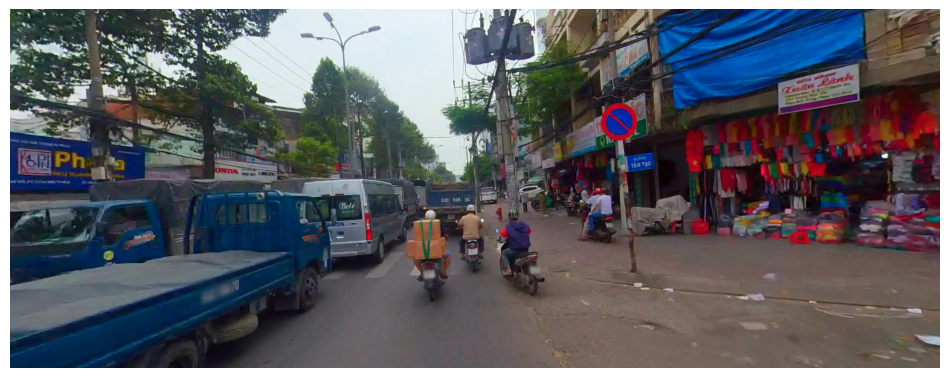

In [4]:
model.eval()  # Ở chế độ eval(), chỉ truyền images, KHÔNG truyền targets
with torch.no_grad():
    preds = model(images)

# Lấy kết quả của ảnh thứ 2 (17.png)
pred = preds[1]
print("Số box model đoán ra:", len(pred["boxes"]))
print("Top 5 scores:", pred["scores"][:5])

# Vẽ ảnh 17.png cùng các box có score > 0.3
img_np = images[1].permute(1, 2, 0).numpy()
fig, ax = plt.subplots(figsize=(12, 5))
ax.imshow(img_np)

for box, label, score in zip(pred["boxes"], pred["labels"], pred["scores"]):
    if score < 0.3:
        continue
    x1, y1, x2, y2 = box.tolist()
    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="lime", facecolor="none")
    ax.add_patch(rect)
    name = cat_names.get(label.item(), str(label.item()))
    ax.text(x1, max(0, y1 - 6), f"{name} ({score:.2f})", color="lime", fontsize=10, fontweight="bold")

plt.axis("off")
plt.show()